# Can acoustic landmarks rescue a neural music search?
Two queries can return the same title for different reasons. Cosine measures how alike two windows sound. A local landmark match asks whether multiple spectral peaks line up at one time offset after a change of speed or pitch. Here both methods see the same five LSH candidates.

Run all cells with Python 3, NumPy, pandas, Matplotlib and IPython. The committed scores are sufficient to refit every rule and regenerate the report figure on CPU. The [experiment notes](../reports/recording-landmarks.md) describe the full GPU run and how the recording groups were formed.

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'reports/landmark-scores.npz').is_file())
sys.path.insert(0, str(root / 'scripts'))
from landmark_evaluation import evaluate

reports = root / 'reports'
with np.load(reports / 'landmark-scores.npz', allow_pickle=False) as saved:
    scores = {key: saved[key] for key in saved}
study = evaluate(scores)
assert study == json.loads((reports / 'landmark-results.json').read_text())
pd.DataFrame({'phase': scores['phase'], 'known': scores['known'], 'group': scores['group_id']}).groupby(
    ['phase', 'known']).group.agg(clips='size', recording_groups='nunique')

clips  recording_groups
phase       known                         
development False    512               256
            True     512               256
test        False    512               256
            True     512               256

## What happens to the listener's answer?
Each row uses the same 512 held-out known clips and 512 held-out absent clips. The 1% setting permits five absent-clip accepts on **development**. Freeze the fusion weight and both cutoffs before counting held-out outcomes. The landmark-only row still gets its candidates from neural LSH. The closed-set column uses a separate rule chosen on development to favour correct first-place titles when every query receives an answer.

In [2]:
methods = {'cosine': 'LSH / cosine', 'landmarks_only': 'Landmarks in shortlist', 'fusion': 'Cosine + landmarks'}
points = [r for r in study['runs'] if r['target'] == 0.01]
closed = {r['method']: r['test']['closed_top1'] for r in study['runs'] if r['target'] is None}
rows = []
for point in points:
    t = point['test']
    rows.append([methods[point['method']], closed[point['method']], t['correct'], t['wrong_known'],
                 t['known'] - t['correct'] - t['wrong_known'], t['false_accepts'], point['strict_id_correct_accepted']])
display(pd.DataFrame(rows, columns=['Ranking', 'Closed top-1', 'Correct accepted', 'Wrong known title',
                                   'Known declined', 'Absent accepted', 'Exact file ID accepted']))
print('Correct recording in the five candidates:', study['top5'], '/ 512')
print('Paired correct decisions:', study['paired'])

,Ranking,Closed top-1,Correct accepted,Wrong known title,Known declined,Absent accepted,Exact file ID accepted
0,LSH / cosine,472,344,0,168,8,342
1,Landmarks in shortlist,485,419,1,92,9,415
2,Cosine + landmarks,488,418,1,93,9,414


Correct recording in the five candidates: 490 / 512
Paired correct decisions: {'retained': 314, 'lost': 30, 'gained': 104, 'paired_change_pp_ci': [9.9609375, 19.140625], 'gained_by_promoting_candidate': 10, 'gained_by_accepting_previous_winner': 94, 'closed_promoted': 16, 'closed_demoted': 0, 'paired_closed_change_pp_ci': [1.7578125, 4.6875]}


## Recognition across rejection budgets
The dots on the right use the **observed held-out** false-accept rate. Every operating point was chosen independently on development songs, so the held-out points need not form a monotonic curve. The star marks the 1% development target. The top-five figure is the upper limit for a reranker using this shortlist.

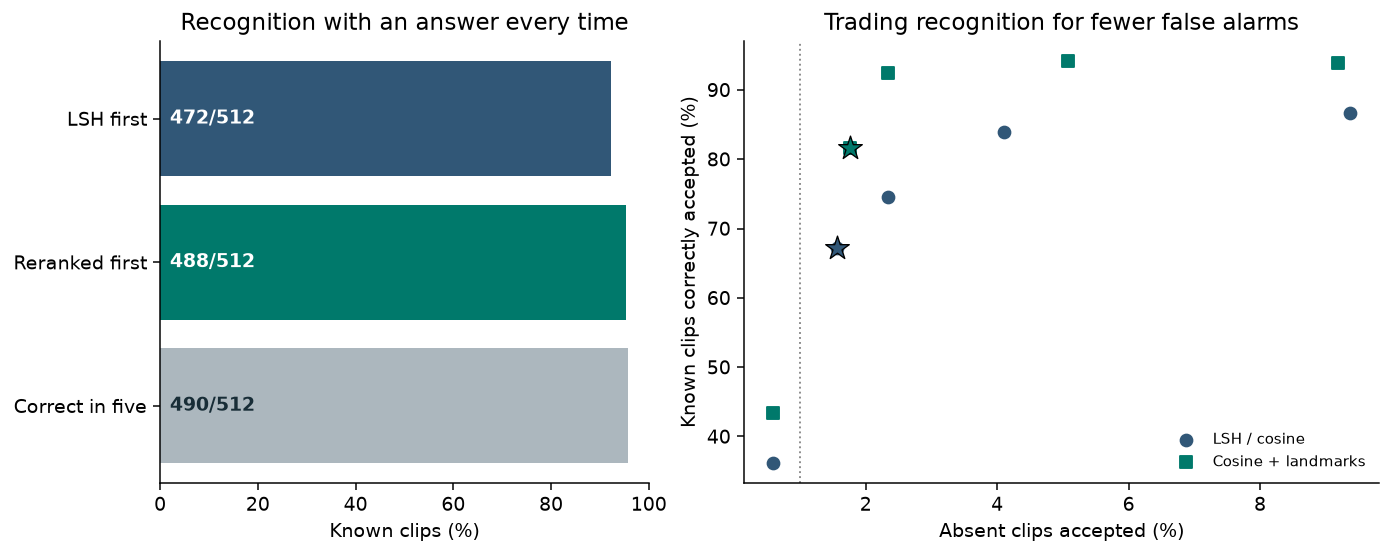

In [3]:
from io import BytesIO
fig, (left, right) = plt.subplots(1, 2, figsize=(10.2, 4), layout='constrained',
                                gridspec_kw={'width_ratios': [1, 1.3]})
palette = {'cosine': '#315777', 'fusion': '#00796b'}
labels = ['LSH first', 'Reranked first', 'Correct in five']
hits = [closed['cosine'], closed['fusion'], study['top5']]
left.barh(labels, np.array(hits) / 512 * 100, color=['#315777', '#00796b', '#acb7be'])
for i, count in enumerate(hits):
    left.text(2, i, f'{count}/512', va='center', color='white' if i < 2 else '#182d37', weight='bold')
left.set(xlim=(0, 100), xlabel='Known clips (%)', title='Recognition with an answer every time')
left.invert_yaxis()
for key, marker in [('cosine', 'o'), ('fusion', 's')]:
    runs = [r for r in study['runs'] if r['method'] == key and r['target'] is not None]
    xy = [(100*r['test']['false_accepts']/r['test']['unknown'], 100*r['test']['correct']/r['test']['known']) for r in runs]
    right.scatter(*zip(*xy), marker=marker, s=40, color=palette[key], label=methods[key])
    right.scatter(*xy[next(i for i,r in enumerate(runs) if r['target']==.01)], marker='*', s=175,
                  color=palette[key], edgecolor='black', linewidth=.7, zorder=4)
right.axvline(1, ls=':', color='#888', lw=1)
right.set(xlabel='Absent clips accepted (%)', ylabel='Known clips correctly accepted (%)',
          title='Trading recognition for fewer false alarms')
right.legend(frameon=False, fontsize=8, loc='best')
for ax in (left,right):
    ax.spines[['top','right']].set_visible(False)
fig.savefig(reports/'recording-landmarks.pdf', bbox_inches='tight')
preview=BytesIO()
fig.savefig(preview, format='png', dpi=135, bbox_inches='tight')
plt.close(fig)
display(Image(data=preview.getvalue()))

Two clips from one recording share acoustics. The paired uncertainty calculation resamples whole recording groups. The timing comparison starts from a decoded clip and distinguishes feature extraction, first-stage search and added verification. Synthetic distortions, the chosen shortlist and incomplete duplicate discovery limit the claim to this experiment.